# Lab 3 Pre-Lab: Neural Networks & Computer Vision Basics

You are NOT allowed to import any other libraries in this notebook otherwise points will be deducted. If you need to, please confirm with the TA.
`''' TODO '''` Indicates where your solution code should go. Please ensure code is readable easily.

For a further resource to the material covered in class, please check the following link. It is an introduction to constructing a simple neural network including ReLU and sigmoid activation functions, please read this tutorial before completing the prelab: [Deep Neural Network Step by Step](https://massivefile.com/Building_your_Deep_Neural_Network/).


## 1. Simple Neural Network

For this task, you'll implement a rudimentary neural network with one hidden layer.

**Network Architecture:**

- **Input Layer:**
   - 3 neurons
- **Hidden Layer:**
   - 6 neurons
   - Weight matrix `W1` and bias vector `b1`
   - Activation: ReLU
- **Output Layer:**
   - 4 neurons
   - Weight matrix `W2` and bias vector `b2`
   - Activation: Sigmoid

**Tasks:**

1. **Activation Function:**
   - Implement the ReLU and sigmoid activation functions manually, without using external libraries for this purpose.
      - The ReLU activation function is defined as:

          `ReLU(z) = max(0, z)`

      - The sigmoid activation function is defined as:

          `σ(z) = 1 / (1 + e^(−z))`


2. **Initialization:**
   - Create an input vector `X` with 3 random values between 0 and 1.
   - Based on the network architecture, initialize the weight matrices `W1` and `W2` with random values between 0 and 1.
   - Similarly, initialize the bias vectors `b1` and `b2` with random values between 0 and 1.

   You can use `np.random.rand()`

3. **Forward Pass:**
   - Using the initialized values and considering the specified network architecture, perform the forward pass through the network. Make sure to:
     - Compute the activations for the hidden layer.
     - Apply the ReLU activation function.
     - Compute the activations for the output layer.
     - Apply the sigmoid activation function to get the final output.

4. **Display the Result:**
   - Print the final output from the neural network.

**Note:**
Ensure the matrices' shapes are compatible throughout the network. Do not use external libraries for the forward pass. You are not allowed to import any other libraries.


In [1]:
import numpy as np
np.random.seed(42) # Do not modify

# Activation Functions

E = 2.718281828459045 # Eulers number

def relu(z):
    # max (0,z) applied element wise 
    return np.where( z > 0, z, 0.0)

def sigmoid(z):
    # 1 / (1 + e^9-z)) applied elementwise 
    return 1.0 / (1.0 + E ** (-z))

# 1. Initialization
X = np.random.rand(3)          #input vector, sha[e (3,)
W1 = np.random.rand(6,3)       # hidden weights, shape (6,3)
W2 = np.random.rand(4,6)       # output weights, shape (4,6)
b1 = np.random.rand(6)         # hidden bias, shape (6,)
b2 = np.random.rand(4)         # output bias, shape (4,)

# 2. Forward Pass
Z1 = np.dot(W1, X) + b1        # hidden pre-activation shape 
A1 = relu(Z1)                  # hidden activaiton shape (6,)
Z2 = np.dot(W2, A1) + b2       # output pre activation shape (4,)
A2 = sigmoid(Z2)               # final output, shape (4,)

# 3. Display the Result
print("Final Output A2:")
print(A2)


Final Output A2:
[0.97339443 0.97209919 0.99846254 0.96810729]


## 3.3 Images
You can use the `imshow` function to show images. Here is an example:

/tmp/ipykernel_857/996636489.py:7: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = imageio.imread('cat.jpg')


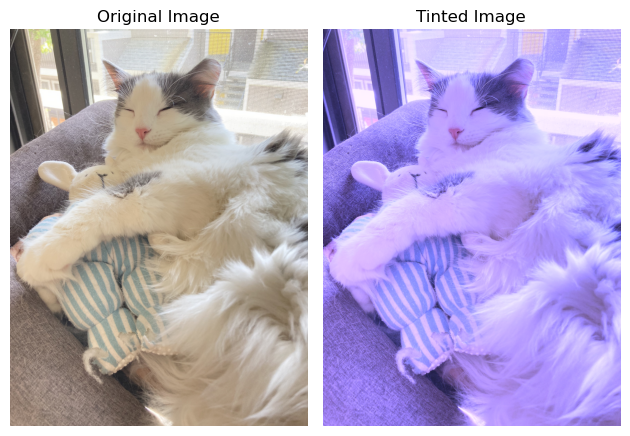

In [2]:
import numpy as np
import imageio
import matplotlib.pyplot as plt
from skimage.transform import resize

# Read an image from the 'assets' folder using imageio
img = imageio.imread('cat.jpg')
# Tint the image by scaling each color channel
img_tinted = img * [1, 0.95, 2]

# A slight gotcha with imshow is that it might give strange results
# if presented with data that is not uint8. To work around this, we
# explicitly cast the image to uint8 before displaying it.
img_tinted = np.clip(img_tinted, 0, 255).astype(np.uint8)

# Show the original image
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Original Image')
plt.axis('off')  # Remove axes

# Show the tinted image
plt.subplot(1, 2, 2)
plt.imshow(img_tinted)
plt.title('Tinted Image')
plt.axis('off')  # Remove axes

# Display both images
plt.tight_layout()
plt.show()


In [3]:
pip install scikit-image

Note: you may need to restart the kernel to use updated packages.


## 2. Image Manipulations

You will be working with and manipulating either `messi.jpeg` or `cat.jpg` which is found in your repos.

**Tasks:**

1. **Image Display:**
   Load image`'messi.jpeg'` or `'cat.jpeg'` using PIL. Display the loaded image using matplotlib. You may find `open()` from PIL and `imshow()` from matplotlib useful.

2. **Image to Numpy Array:**
   Convert the image into a NumPy array and print its shape.

3. **Color Channels:**
   Split the image into its R, G, B channels and display each channel separately.

4. **Grayscale Conversion:**
   Convert the image to grayscale and display the grayscale image.

5. **Image Normalization:**
   Normalize the grayscale image such that values are in the range [0,1]. Print the minimum and maximum values before and after normalization.

6. **Image Crop:**
   Extract a center crop of 500x500 from the grayscale image and display the resized image.

7. **Convolution with Sobel Kernel:**
Manually apply convolution (do not use built-in functions like `numpy.convolve` or `scipy.signal.convolve2d`) to the cropped 500x500 image using the Sobel kernel provided below. Display the convoluted image.
   
   Sobel kernel:
   `[[-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]]`


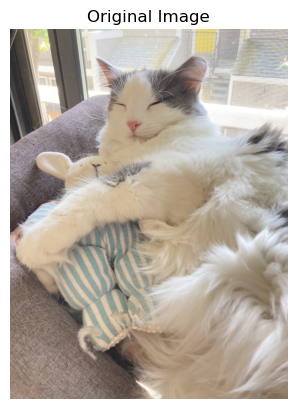

Image shape: (4032, 3024, 3)


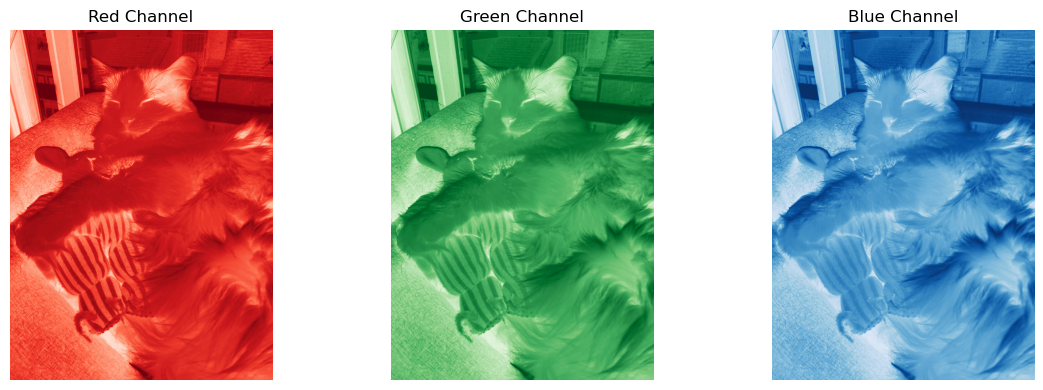

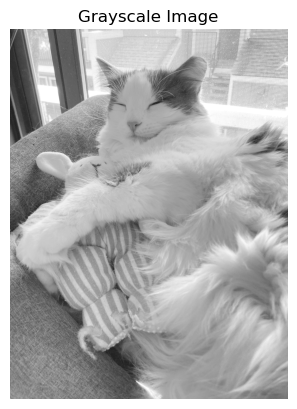

Before normalization -> min: 0.7118 max: 254.97449999999998
After normalization  -> min: 0.0 max: 1.0


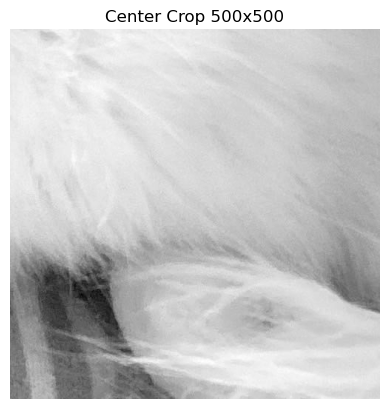

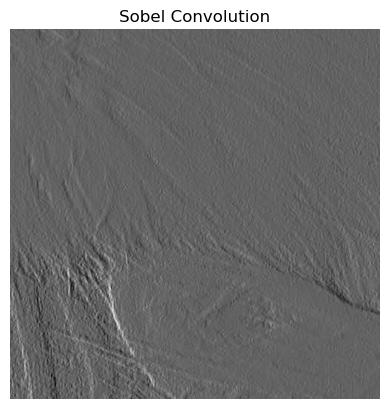

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# 1. Load the image using PIL & Display
img_pil = Image.open('cat.jpg')
plt.imshow(img_pil)
plt.title('Original Image')
plt.axis('off')
plt.show()

# 2. Image to Numpy Array
img = np.array(img_pil)
print("Image shape:", img.shape)

# 3. Color Channels
R = img[:, :, 0]
G = img[:, :, 1]
B = img[:, :, 2]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, channel, name, cmap in zip(
        axes, [R, G, B], ['Red', 'Green', 'Blue'], ['Reds', 'Greens', 'Blues']):
    ax.imshow(channel, cmap=cmap)
    ax.set_title(f'{name} Channel')
    ax.axis('off')
plt.tight_layout()
plt.show()

# 4. Grayscale Conversion (standard luminance weights)
gray = 0.2989 * R + 0.5870 * G + 0.1140 * B
plt.imshow(gray, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')
plt.show()

# 5. Image Normalization
print("Before normalization -> min:", gray.min(), "max:", gray.max())
gray_norm = (gray - gray.min()) / (gray.max() - gray.min())
print("After normalization  -> min:", gray_norm.min(), "max:", gray_norm.max())

# 6. Image Center Crop (500x500)
h, w = gray_norm.shape
crop_size = 500
top = (h - crop_size) // 2
left = (w - crop_size) // 2
cropped = gray_norm[top:top + crop_size, left:left + crop_size]
plt.imshow(cropped, cmap='gray')
plt.title('Center Crop 500x500')
plt.axis('off')
plt.show()

# 7. Convolution with Sobel Kernel (manual, no built-in convolution)
sobel = np.array([[-1, 0, 1],
                  [-2, 0, 2],
                  [-1, 0, 1]])

ch, cw = cropped.shape
out_h, out_w = ch - 2, cw - 2  # "valid" output size for a 3x3 kernel
convolved = np.zeros((out_h, out_w))

for i in range(out_h):
    for j in range(out_w):
        region = cropped[i:i + 3, j:j + 3]
        convolved[i, j] = np.sum(region * sobel)

plt.imshow(convolved, cmap='gray')
plt.title('Sobel Convolution')
plt.axis('off')
plt.show()